In [2]:
import cv2
import numpy as np
import sys
import os
import matplotlib.pyplot as plt
import tkinter as tk
from tkinter import filedialog

In [3]:
# --- 參數設定 ---
MIN_BREAD_AREA = 2000    # 麵包最小面積
MIN_PLATE_AREA = 10000   # 盤子最小面積
MAX_AREA_RATIO = 0.5
MARGIN_RATIO = 0.05
ASPECT_RATIO_RANGE = (0.2, 5.0)

# --- Jupyter 顯示圖片專用函式 ---
def show_img_inline(title, img):
    """將 OpenCV (BGR) 轉為 Matplotlib (RGB) 並在 Notebook 內顯示"""
    if img is None:
        print(f"❌ {title}: 圖片是空的")
        return
    
    # BGR 轉 RGB
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    plt.figure(figsize=(10, 8))
    plt.title(title)
    plt.imshow(img_rgb)
    plt.axis('off')
    plt.show()

In [ ]:
def process_bread_image(img_path):
    # 支援中文路徑讀取
    img = cv2.imdecode(np.fromfile(img_path, dtype=np.uint8), cv2.IMREAD_COLOR)
    if img is None: 
        print(f"❌ 無法讀取圖片: {img_path}")
        return

    h_img, w_img, _ = img.shape
    img_center_x = w_img // 2
    img_center_y = h_img // 2
    
    # 複製一份用來畫圖
    debug_img = img.copy()

    # ==========================================
    # 1. 第一階段：尋找盤子 (Plate Hunter)
    # ==========================================
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blur_plate = cv2.GaussianBlur(gray, (25, 25), 0)
    # 正向二值化 (找白盤子)
    _, binary_plate = cv2.threshold(blur_plate, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    contours_plate, _ = cv2.findContours(binary_plate, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    plate_bbox = None
    if len(contours_plate) > 0:
        sorted_plates = sorted(contours_plate, key=cv2.contourArea, reverse=True)
        if cv2.contourArea(sorted_plates[0]) > MIN_PLATE_AREA:
            plate_bbox = cv2.boundingRect(sorted_plates[0])

    # 設定搜尋範圍
    if plate_bbox:
        px, py, pw, ph = plate_bbox
        # 畫出盤子框 (藍色)
        cv2.rectangle(debug_img, (px, py), (px+pw, py+ph), (255, 0, 0), 2)
        
        search_img = img[py:py+ph, px:px+pw] 
        offset_x, offset_y = px, py        
    else:
        print("未取得盤子位置，切換為全圖搜尋")
        search_img = img
        offset_x, offset_y = 0, 0

    # ==========================================
    # 2. 第二階段：尋找麵包 (Bread Hunter)
    # ==========================================
    search_gray = cv2.cvtColor(search_img, cv2.COLOR_BGR2GRAY)
    search_blur = cv2.GaussianBlur(search_gray, (15, 15), 0)
    # 反向二值化 (找深色麵包)
    _, binary_bread = cv2.threshold(search_blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 13))
    binary_bread = cv2.morphologyEx(binary_bread, cv2.MORPH_CLOSE, kernel)
    
    contours, _ = cv2.findContours(binary_bread, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    candidates = []
    sh, sw = search_img.shape[:2]
    search_center_x, search_center_y = sw // 2, sh // 2

    for c in contours:
        area = cv2.contourArea(c)
        bx, by, bw, bh = cv2.boundingRect(c) 
        
        if area < MIN_BREAD_AREA: continue
        
        aspect_ratio = float(bw) / bh
        if aspect_ratio < ASPECT_RATIO_RANGE[0] or aspect_ratio > ASPECT_RATIO_RANGE[1]:
            continue

        # 中央優先 (相對於搜尋範圍中心)
        obj_center_x = bx + bw / 2
        obj_center_y = by + bh / 2
        dist = np.sqrt((obj_center_x - search_center_x)**2 + (obj_center_y - search_center_y)**2)
        
        candidates.append({'dist': dist, 'bbox': (bx, by, bw, bh)})

    # ==========================================
    # 3. 選出主角並顯示
    # ==========================================
    if len(candidates) > 0:
        candidates.sort(key=lambda k: k['dist'])
        
        winner = candidates[0]
        bx, by, bw, bh = winner['bbox']
        
        # 還原座標
        x = bx + offset_x
        y = by + offset_y
        w = bw
        h = bh
        
        # 畫出麵包框 (綠色)
        cv2.rectangle(debug_img, (x, y), (x+w, y+h), (0, 255, 0), 3)
        # 因為移除 AI 了，這裡顯示通用文字
        text = "Target Found"
        cv2.putText(debug_img, text, (x, y-10), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
        
        print(f"✅ 目標鎖定！距離中心: {winner['dist']:.1f} 像素")
    else:
        print("❌ 無目標物體被偵測到。")

    # 畫中心點
    cv2.drawMarker(debug_img, (img_center_x, img_center_y), (255, 0, 0), markerType=cv2.MARKER_CROSS, thickness=2)

    # 顯示結果 (使用 Matplotlib)
    show_img_inline("Detect Result", debug_img)

請在彈出的視窗中選擇圖片...
📖 讀取路徑: D:/Project/ML/Bread_classifier/data/test/garlic_parsley/opencv_20250806_120442_079138.png
✅ 目標鎖定！距離中心: 63.6 像素


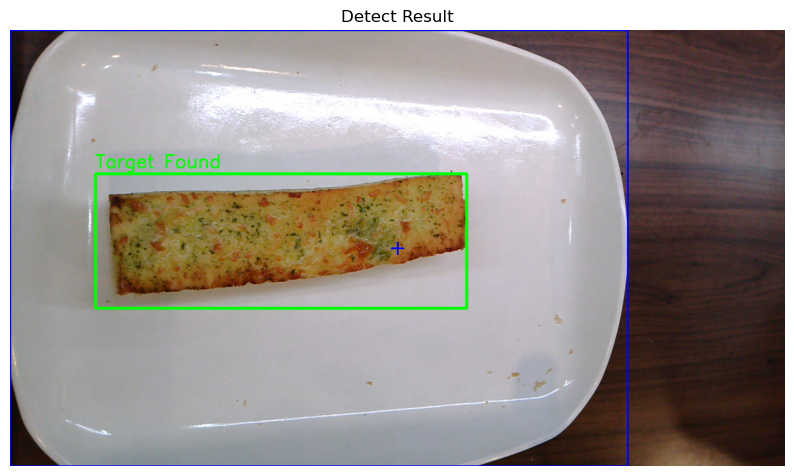

In [5]:
# 建立隱藏的 root 視窗
root = tk.Tk()
root.withdraw() # 隱藏主視窗
root.call('wm', 'attributes', '.', '-topmost', True) # 讓彈出視窗在最上層

print("請在彈出的視窗中選擇圖片...")

img_path = filedialog.askopenfilename(
    title="請選擇圖片",
    filetypes=[("Image Files", "*.jpg;*.jpeg;*.png;*.bmp")]
)

if img_path:
    print(f"📖 讀取路徑: {img_path}")
    process_bread_image(img_path)
else:
    print("❌ 未選擇檔案")